In [76]:
# ===== 팀 프로젝트 시작 셀 =====
import os, sys
from google.colab import userdata

TOKEN = userdata.get('GITHUB_TOKEN')
NAME = "yurim"
REPO_URL = "github.com/DA15-Lab/team3-ping-analytics.git"
PROJECT_DIR = "/content/team3-ping-analytics"

if not os.path.exists(PROJECT_DIR):
    !git clone -q https://{TOKEN}@{REPO_URL}
    %cd {PROJECT_DIR}
else:
    %cd {PROJECT_DIR}
    !git pull -q

!git config user.email "{NAME}@example.com"
!git config user.name "{NAME}"

!pip install -q -r requirements.txt

sys.path.append("/content/team3-ping-analytics/src")
import preprocessing as preprocess

print(preprocess.module_test())
print("✅ 준비 완료")

/content/team3-ping-analytics
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 61.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
✅ 모듈 설치 완료
✅ 준비 완료


In [ ]:
# ===== 작업 저장 셀 =====
NAME = "유림"
PROJECT_DIR = "/content/team3-ping-analytics"

%cd {PROJECT_DIR}
!git config pull.rebase false
!git config core.editor "true"
!git pull
!pip install -q -r requirements.txt

from google.colab import _message
import json

with open('notebooks/전처리+문제제기_분석.ipynb', 'w') as f:
    json.dump(_message.blocking_request('get_ipynb', timeout_sec=30)['ipynb'], f)

!pip freeze | grep -v "google-colab" > requirements.txt

!git add .
!git commit -m "최종본 작성 완료!"
!git push

/content/team3-ping-analytics
Already up to date.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 101.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [46]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [47]:
import os
import ast
import pandas as pd
import numpy as np
from scipy import stats

DATA_DIR = '/content/drive/MyDrive/00_원본 csv'

def path(name):
    return f'{DATA_DIR}/{name}'

print('설정 완료. DATA_DIR =', DATA_DIR)

설정 완료. DATA_DIR = /content/drive/MyDrive/00_원본 csv


In [48]:
# 다른 테이블 FK검증할 때 기준으로 쓸 기본 테이블
user = pd.read_csv(path('accounts_user.csv'))
print(user.shape)
valid_ids = set(user['id'])
user['created_at'] = pd.to_datetime(user['created_at'])
signup = user.set_index('id')['created_at']

(677085, 16)


In [49]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 나눔고딕 폰트 설치 (최초 1회, 몇 초 걸림) 후 matplotlib에 등록
!apt-get -qq -y install fonts-nanum > /dev/null 2>&1

font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 기호 깨짐 방지

# 차트 공통 스타일
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25

# 공통 색상 팔레트 (카테고리 구분용 — 항상 이 순서로만 사용)
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'

print('폰트/색상 설정 완료')

폰트/색상 설정 완료


# 전처리

## 1. accounts_friendrequest
- id 중복, 전체 행 중복, 자기참조(본인→본인 요청), FK 위반(없는 유저id) 여부 검증
- 전부 0건으로 문제 없음 → 필터링 없이 그대로 사용

In [50]:
friendrequest = pd.read_csv(path('accounts_friendrequest.csv'))
print('원본 shape:', friendrequest.shape)
print(friendrequest['status'].value_counts())

assert friendrequest['id'].duplicated().sum() == 0, 'id 중복 발견'
assert friendrequest.duplicated().sum() == 0, '전체 행 중복 발견'

friendrequest['created_at'] = pd.to_datetime(friendrequest['created_at'])
friendrequest['updated_at'] = pd.to_datetime(friendrequest['updated_at'])
print('날짜 범위:', friendrequest['created_at'].min(), '~', friendrequest['created_at'].max())

self_request = (friendrequest['send_user_id'] == friendrequest['receive_user_id']).sum()
invalid_receive = (~friendrequest['receive_user_id'].isin(valid_ids)).sum()
invalid_send = (~friendrequest['send_user_id'].isin(valid_ids)).sum()
assert self_request == 0 and invalid_receive == 0 and invalid_send == 0, '비정상 케이스 발견'

print('검증 통과 (자기참조 0건, FK 위반 0건) — 필터링 없이 그대로 사용')
print('전처리 완료 shape:', friendrequest.shape)

원본 shape: (17147175, 6)
status
A    12878407
P     3938608
R      330160
Name: count, dtype: int64
날짜 범위: 2023-04-17 18:29:11 ~ 2024-05-09 09:21:47
검증 통과 (자기참조 0건, FK 위반 0건) — 필터링 없이 그대로 사용
전처리 완료 shape: (17147175, 6)


## 2. accounts_userwithdraw
- reason 분포 확인 결과 admin, test 사유가 섞여 있음 -> 실제 탈퇴가 아니라 운영/테스트 계정이므로 분석 대상에서 제외
- 제외 후 70,764건 → 70,650건

In [51]:
userwithdraw_raw = pd.read_csv(path('accounts_userwithdraw.csv'))
print('원본 shape:', userwithdraw_raw.shape)
print(userwithdraw_raw['reason'].value_counts())

userwithdraw = userwithdraw_raw[~userwithdraw_raw['reason'].isin(['admin', 'test'])].copy()
userwithdraw['created_at'] = pd.to_datetime(userwithdraw['created_at'])
print()
print('admin/test 제외 후 shape:', userwithdraw.shape)
print('날짜 범위:', userwithdraw['created_at'].min(), '~', userwithdraw['created_at'].max())

원본 shape: (70764, 3)
reason
기타 이유           40301
함께 할 친구가 없어서    14450
재밌는 질문이 없어서     13133
버그가 너무 많아서       2031
구독료가 너무 비싸서       730
admin              61
test               53
기타                  5
Name: count, dtype: int64

admin/test 제외 후 shape: (70650, 3)
날짜 범위: 2023-03-29 13:22:12 ~ 2024-05-09 08:49:06


## 3. accounts_user_contacts
- id 중복 0건, 전체 행 중복 0건, user_id FK 위반 0건
- contacts_count에 음수나 비정상 큰 값 없음 (0~114) → 필터링 없이 그대로 사용

In [52]:
contacts = pd.read_csv(path('accounts_user_contacts.csv'))
print('shape:', contacts.shape)

assert contacts['id'].duplicated().sum() == 0
assert contacts.duplicated().sum() == 0
assert (~contacts['user_id'].isin(valid_ids)).sum() == 0
print(contacts['contacts_count'].describe())

def _invite_count(x):
    try:
        v = ast.literal_eval(x)
        return len(v) if isinstance(v, list) else 0
    except Exception:
        return 0

contacts['invite_count'] = contacts['invite_user_id_list'].apply(_invite_count)
print('검증 통과 — 필터링 없이 그대로 사용')

shape: (5063, 4)
count    5063.000000
mean       25.986174
std        13.601434
min         0.000000
25%        16.000000
50%        24.000000
75%        34.000000
max       114.000000
Name: contacts_count, dtype: float64
검증 통과 — 필터링 없이 그대로 사용


## 4. polls_usercandidate
- id 중복 0건, 전체 행 중복 0건, user_id FK 위반 0건 → 필터링 없이 그대로 사용

In [53]:
candidate = pd.read_csv(path('polls_usercandidate.csv'))
print('shape:', candidate.shape)

assert candidate['id'].duplicated().sum() == 0
assert candidate.duplicated().sum() == 0
candidate['created_at'] = pd.to_datetime(candidate['created_at'])
assert (~candidate['user_id'].isin(valid_ids)).sum() == 0
print('날짜 범위:', candidate['created_at'].min(), '~', candidate['created_at'].max())
print('검증 통과 — 필터링 없이 그대로 사용')

shape: (4769609, 4)
날짜 범위: 2023-04-28 12:27:49 ~ 2024-05-08 01:36:18
검증 통과 — 필터링 없이 그대로 사용


# 분석 코드

## 분석 테이블 로드

In [54]:
CLEAN_DIR = '/content/drive/MyDrive/01_전처리 완료된 csv'

def clean_path(name):
    return f'{CLEAN_DIR}/{name}'

In [55]:
att = pd.read_csv(clean_path('accounts_attendance_clean.csv'), usecols=['user_id', 'attendance_date'])
att['attendance_date'] = pd.to_datetime(att['attendance_date'])

group = pd.read_csv(path('accounts_group.csv'), usecols=['id', 'school_id'])

uqr = pd.read_csv(path('accounts_userquestionrecord.csv'), usecols=['user_id', 'created_at'])
uqr['created_at'] = pd.to_datetime(uqr['created_at'])
uqr = uqr.merge(signup.rename('signup_ts'), left_on='user_id', right_index=True, how='inner')
uqr['elapsed_hours'] = (uqr['created_at'] - uqr['signup_ts']).dt.total_seconds() / 3600

qset = pd.read_csv(clean_path('polls_questionset_clean.csv'), usecols=['user_id', 'created_at'])
qset['created_at'] = pd.to_datetime(qset['created_at'])
assigned_users = set(qset['user_id'].dropna().unique())

print('로드 완료:', len(att), '출석 /', len(group), '그룹 /', len(uqr), '투표기록 /', len(qset), '질문세트 배정')

로드 완료: 2222327 출석 / 84515 그룹 / 1217558 투표기록 / 158384 질문세트 배정


## 가입 추이와 초기 활성 유저 비율 분석

In [56]:
# 전체 가입자 수, 그 중 2023년 5월 가입자 수/비중 계산
total_users = len(user)
may_mask = (user['created_at'] >= '2023-05-01') & (user['created_at'] < '2023-06-01')
may_users = may_mask.sum()
print(f"전체 가입자: {total_users:,}명")
print(f"2023년 5월 가입: {may_users:,}명 ({may_users/total_users*100:.2f}%)")

# 투표 기록(uqr)의 elapsed_hours(가입 후 경과시간)를 24로 나눠서 "가입 후 며칠째"인지 계산
uqr['day_idx'] = (uqr['elapsed_hours'] // 24).astype(int)

# 가입 당일(Day 0), 28일 후(Day 28)에 실제 투표 활동이 있었던 유저 수 집계
day0_active = uqr.loc[uqr['day_idx'] == 0, 'user_id'].nunique()
day28_active = uqr.loc[uqr['day_idx'] == 28, 'user_id'].nunique()
print()
print(f"Day 0 활성 유저 비율: {day0_active/total_users*100:.2f}%  ({day0_active:,}명)")
print(f"Day 28 활성 유저 비율: {day28_active/total_users*100:.2f}%  ({day28_active:,}명)")

전체 가입자: 677,085명
2023년 5월 가입: 635,505명 (93.86%)

Day 0 활성 유저 비율: 0.63%  (4,241명)
Day 28 활성 유저 비율: 0.04%  (295명)


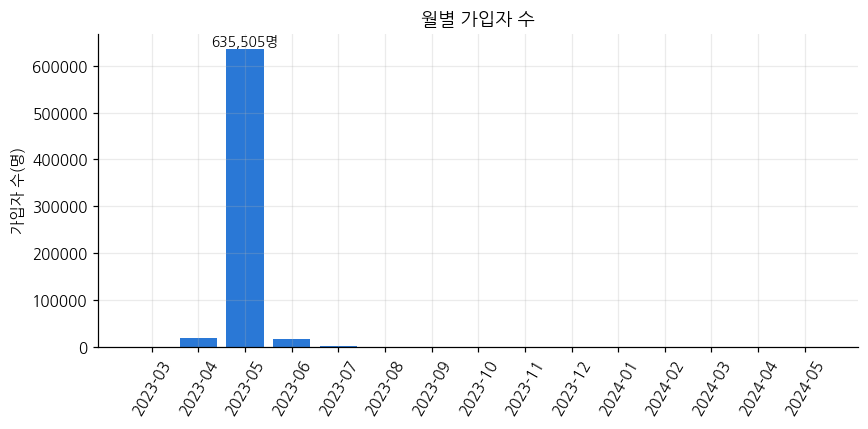

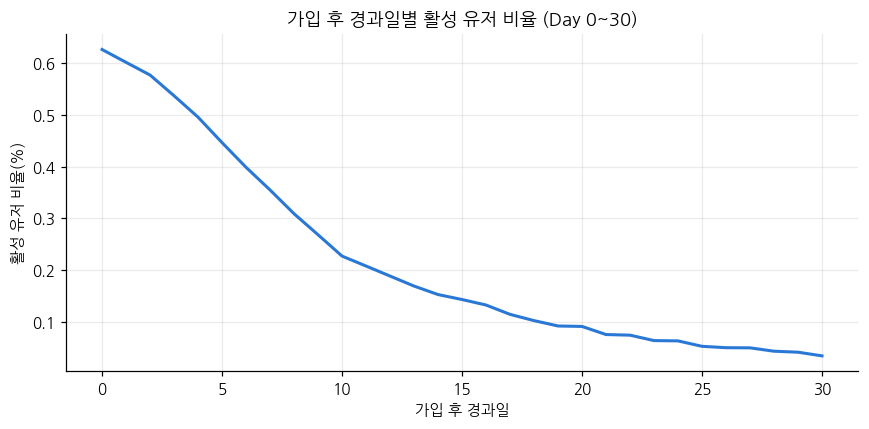

In [57]:
# 차트1:월별 가입자 수 (5월 집중을 보여줌)
monthly_signup = user['created_at'].dt.to_period('M').value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(monthly_signup.index.astype(str), monthly_signup.values, color=BLUE)
ax.set_title('월별 가입자 수')
ax.set_ylabel('가입자 수(명)')
ax.tick_params(axis='x', rotation=60)
# 5월 막대만 값 표시
peak_i = monthly_signup.values.argmax()
ax.annotate(f'{monthly_signup.values[peak_i]:,}명', (peak_i, monthly_signup.values[peak_i]),
            ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

# 차트2: 가입 후 경과일(Day)별 활성 유저 비율 — Day0~Day30
day_counts = uqr.loc[uqr['day_idx'].between(0, 30)].groupby('day_idx')['user_id'].nunique()
day_rate = day_counts / total_users * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(day_rate.index, day_rate.values, color=BLUE, linewidth=2)
ax.set_title('가입 후 경과일별 활성 유저 비율 (Day 0~30)')
ax.set_xlabel('가입 후 경과일')
ax.set_ylabel('활성 유저 비율(%)')
plt.tight_layout()
plt.show()

## 친구요청·탈퇴 추이의 월별 집중도

In [58]:
# 친구요청 전체 건수 중 2023년 5월 건수/비중
fr_total = len(friendrequest)
fr_may = ((friendrequest['created_at'] >= '2023-05-01') & (friendrequest['created_at'] < '2023-06-01')).sum()
print(f"친구요청 전체: {fr_total:,}건 / 5월: {fr_may:,}건 ({fr_may/fr_total*100:.2f}%)")

# 탈퇴 전체 건수(admin/test 제외) 중 2023년 5월 건수/비중
wd_total = len(userwithdraw)
wd_may = ((userwithdraw['created_at'] >= '2023-05-01') & (userwithdraw['created_at'] < '2023-06-01')).sum()
print(f"탈퇴 전체(admin/test 제외): {wd_total:,}건 / 5월: {wd_may:,}건 ({wd_may/wd_total*100:.2f}%)")

# 참고용: admin/test를 제외하지 않은 원본 기준으로도 한 번 더 계산해서 비교
wd_total_raw = len(userwithdraw_raw)
wd_may_raw = ((pd.to_datetime(userwithdraw_raw['created_at']) >= '2023-05-01') &
              (pd.to_datetime(userwithdraw_raw['created_at']) < '2023-06-01')).sum()
print(f"[참고] admin/test 포함(원본) 기준: {wd_may_raw:,}/{wd_total_raw:,} = {wd_may_raw/wd_total_raw*100:.2f}%")

친구요청 전체: 17,147,175건 / 5월: 15,989,697건 (93.25%)
탈퇴 전체(admin/test 제외): 70,650건 / 5월: 44,804건 (63.42%)
[참고] admin/test 포함(원본) 기준: 44,845/70,764 = 63.37%


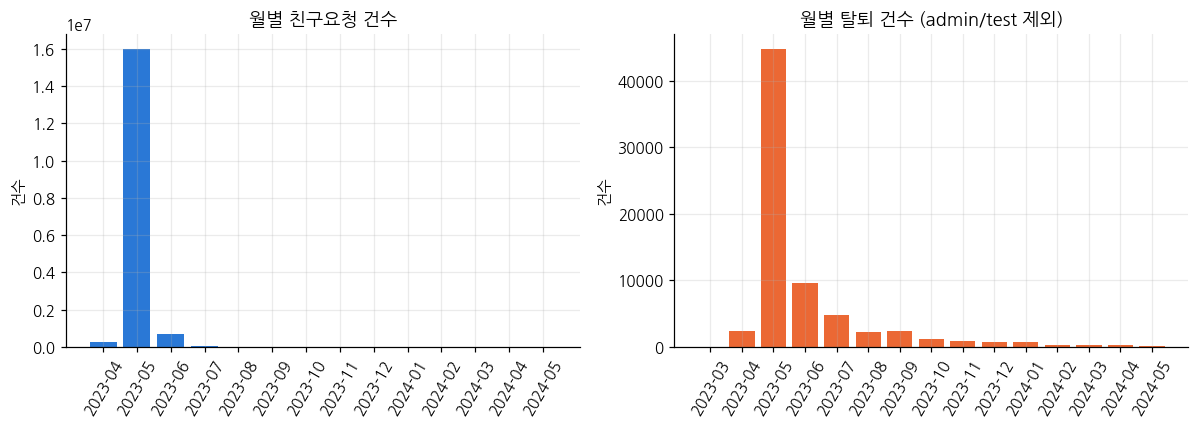

In [59]:
# 친구요청·탈퇴 월별 건수를 나란히 비교 (스케일이 달라서 두 개 패널로 분리 — 한 축에 같이 그리지 않음)
fr_monthly = friendrequest['created_at'].dt.to_period('M').value_counts().sort_index()
wd_monthly = userwithdraw['created_at'].dt.to_period('M').value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(fr_monthly.index.astype(str), fr_monthly.values, color=BLUE)
axes[0].set_title('월별 친구요청 건수')
axes[0].set_ylabel('건수')
axes[0].tick_params(axis='x', rotation=60)

axes[1].bar(wd_monthly.index.astype(str), wd_monthly.values, color=ORANGE)
axes[1].set_title('월별 탈퇴 건수 (admin/test 제외)')
axes[1].set_ylabel('건수')
axes[1].tick_params(axis='x', rotation=60)

plt.tight_layout()
plt.show()

## 가입 시점과 잔존율의 상관관계

In [60]:
# 가입 시각 → 가입월(연-월), 출석 시각 → 활동월(연-월)로 변환
user['signup_month'] = user['created_at'].dt.to_period('M')
att['active_month'] = att['attendance_date'].dt.to_period('M')

# 유저별로 중복 없이 활동한 월 목록을 만든 뒤 각자의 가입월과 이어붙이기
user_month = att[['user_id', 'active_month']].drop_duplicates()
um = user_month.merge(user[['id', 'signup_month']], left_on='user_id', right_on='id', how='left')

# 활동월 - 가입월 = 가입 후 몇 개월째 활동했는지(offset)
um['offset'] = um['active_month'].apply(lambda p: p.ordinal) - um['signup_month'].apply(lambda p: p.ordinal)

# 가입월별 전체 가입자 수, 그 중 가입 1개월 후(offset==1)에 활동한 유저 수
cohort_size = user.groupby('signup_month')['id'].nunique()
active_1m = um[um['offset'] == 1].groupby('signup_month')['user_id'].nunique()

# 1개월 후 잔존율 = 1개월 후 활동 유저 수 / 해당 코호트 전체 가입자 수
cohort = pd.DataFrame({'size': cohort_size, 'active_1m': active_1m}).fillna(0)
cohort['retention_1m'] = cohort['active_1m'] / cohort['size'] * 100
cohort = cohort.sort_index()

# 표본이 거의 없는 첫 달(2023-03)과 마지막 달(2024-05)은 1개월 후 데이터 자체가 없어서 제외
use = cohort.drop(index=[p for p in [pd.Period('2023-03', 'M'), pd.Period('2024-05', 'M')] if p in cohort.index])
print(use[['size', 'retention_1m']])
print()

# 가입월 순서와 1개월 잔존율의 피어슨 상관계수 — 전체 코호트 기준
order_all = np.arange(1, len(use) + 1)
r1, p1 = stats.pearsonr(order_all, use['retention_1m'].values)
print(f"[전체 코호트] 가입월 순서 vs 1개월 잔존율: r={r1:.4f}, p={p1:.4f}")

# 표본이 압도적으로 큰 5월 코호트를 빼고 같은 상관계수를 다시 계산 (5월 때문에 생긴 착시인지 확인)
not_may = np.array([idx != pd.Period('2023-05', 'M') for idx in use.index])
order_wo_may = order_all[not_may]
ret_wo_may = use['retention_1m'].values[not_may]
r2, p2 = stats.pearsonr(order_wo_may, ret_wo_may)
print(f"[5월 제외]   가입월 순서 vs 1개월 잔존율: r={r2:.4f}, p={p2:.4f}")

                size  retention_1m
signup_month                      
2023-04        19060     21.610703
2023-05       635505     33.742929
2023-06        16737     13.765908
2023-07         1849     16.873986
2023-08          524      9.160305
2023-09          605     11.404959
2023-10          409      4.889976
2023-11          731      2.735978
2023-12          231      2.597403
2024-01          455      0.879121
2024-02          255      6.274510
2024-03          446      2.242152
2024-04          196      2.040816

[전체 코호트] 가입월 순서 vs 1개월 잔존율: r=-0.8311, p=0.0004
[5월 제외]   가입월 순서 vs 1개월 잔존율: r=-0.8824, p=0.0001


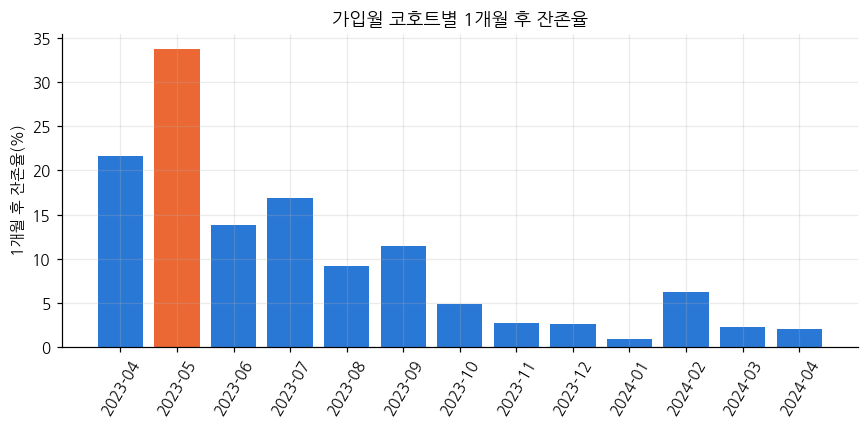

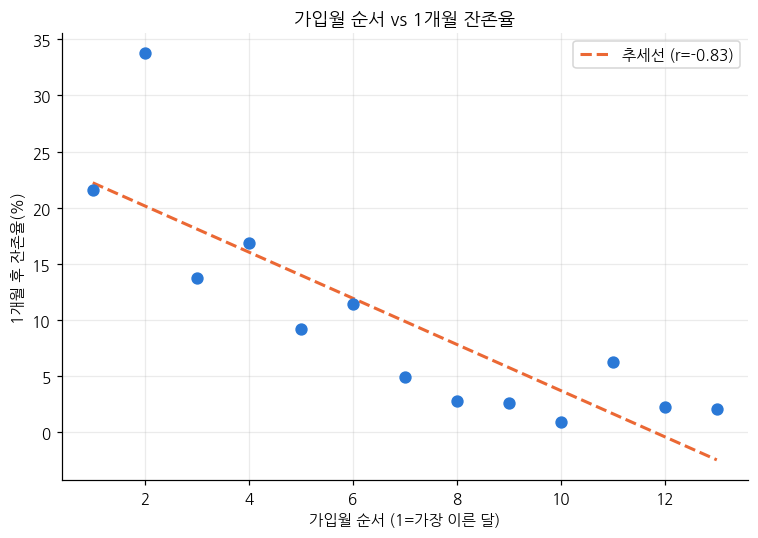

In [61]:
# 차트1: 가입월 코호트별 1개월 후 잔존율 (막대) — 5월 코호트만 강조색으로 구분
colors = [ORANGE if idx == pd.Period('2023-05', 'M') else BLUE for idx in use.index]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(use.index.astype(str), use['retention_1m'], color=colors)
ax.set_title('가입월 코호트별 1개월 후 잔존율')
ax.set_ylabel('1개월 후 잔존율(%)')
ax.tick_params(axis='x', rotation=60)
plt.tight_layout()
plt.show()

# 차트2: 가입월 순서 vs 1개월 잔존율 산점도 + 추세선 (상관계수 r 시각적으로 확인)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(order_all, use['retention_1m'].values, color=BLUE, s=50, zorder=3)
z = np.polyfit(order_all, use['retention_1m'].values, 1)
trend = np.poly1d(z)
ax.plot(order_all, trend(order_all), color=ORANGE, linewidth=2, linestyle='--',
        label=f'추세선 (r={r1:.2f})')
ax.set_title('가입월 순서 vs 1개월 잔존율')
ax.set_xlabel('가입월 순서 (1=가장 이른 달)')
ax.set_ylabel('1개월 후 잔존율(%)')
ax.legend()
plt.tight_layout()
plt.show()

## 탈퇴 사유 분포와 네트워크·콘텐츠 공급 지표

In [62]:
# 탈퇴 사유별 비중
reason_pct_clean = userwithdraw['reason'].value_counts(normalize=True) * 100
reason_pct_raw = userwithdraw_raw['reason'].value_counts(normalize=True) * 100

# 연락처 업로드한 유저 중 1명 이상 초대에 성공한 유저 비율
total_contacts = len(contacts)
success = (contacts['invite_count'] >= 1).sum()
print(f"연락처 업로드 유저: {total_contacts:,}명 / 1명 이상 초대 성공: {success:,}명 "
      f"({success/total_contacts*100:.2f}%)")
print()

# 질문세트 생성량을 월별로 집계해서, 5월 대비 6월 감소율 계산
qset['month'] = qset['created_at'].dt.to_period('M')
monthly = qset['month'].value_counts().sort_index()
may_q, jun_q = monthly.get(pd.Period('2023-05', 'M'), 0), monthly.get(pd.Period('2023-06', 'M'), 0)
print(f"질문세트 생성량 — 5월: {may_q:,}건 → 6월: {jun_q:,}건 "
      f"(감소율 {(may_q-jun_q)/may_q*100:.2f}%)")

연락처 업로드 유저: 5,063명 / 1명 이상 초대 성공: 1,158명 (22.87%)

질문세트 생성량 — 5월: 143,158건 → 6월: 9,563건 (감소율 93.32%)


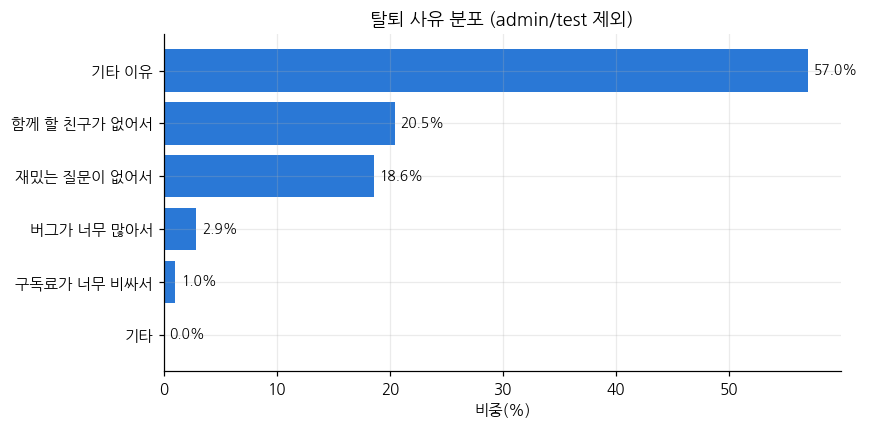

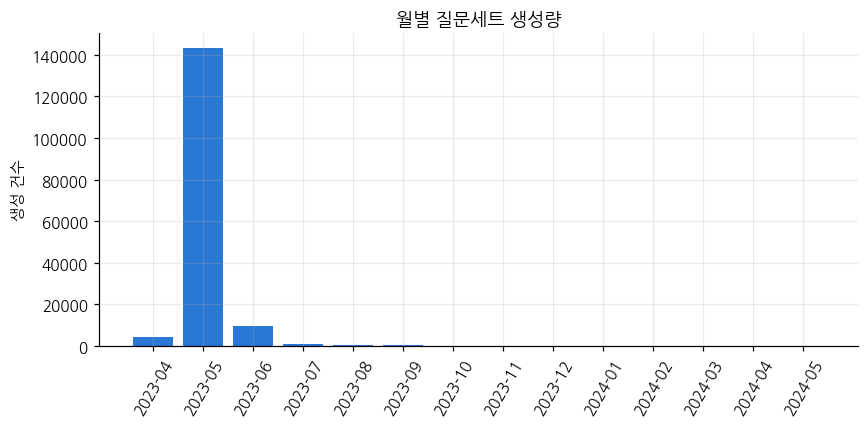

In [63]:
# 차트1: 탈퇴 사유 분포 (admin/test 제외 기준)
reason_sorted = reason_pct_clean.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(reason_sorted.index.astype(str), reason_sorted.values, color=BLUE)
ax.set_title('탈퇴 사유 분포 (admin/test 제외)')
ax.set_xlabel('비중(%)')
for i, v in enumerate(reason_sorted.values):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()

# 차트2: 월별 질문세트 생성량 추이 (5월 급증 후 6월 급감을 보여줌)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(monthly.index.astype(str), monthly.values, color=BLUE)
ax.set_title('월별 질문세트 생성량')
ax.set_ylabel('생성 건수')
ax.tick_params(axis='x', rotation=60)
plt.tight_layout()
plt.show()

## 퍼널(가입->친구요청 송신->질문세트 배정->투표완료)의 전체 가입자 대비 각 단계 도달 비율

In [64]:
# 각 단계에 해당하는 유저 id 집합 만들기
send_users = set(friendrequest['send_user_id'].dropna().unique())   # 친구요청을 보낸 적 있는 유저
vote_users = set(uqr['user_id'].dropna().unique())                  # 투표한 적 있는 유저
all_users = set(user['id'])                                         # 전체 가입자

n0 = len(all_users)
n1 = len(send_users & all_users)        # 가입자 중 친구요청 송신까지 간 사람
n2 = len(assigned_users & all_users)    # 가입자 중 질문세트 배정까지 간 사람
n3 = len(vote_users & all_users)        # 가입자 중 투표 완료까지 간 사람

# 단계별 전체 가입자 대비 도달 비율 출력
print(f"0. 가입          {n0:>8,}  (100.00%)")
print(f"1. 친구요청 송신 {n1:>8,}  ({n1/n0*100:.2f}%)")
print(f"2. 질문세트 배정 {n2:>8,}  ({n2/n0*100:.2f}%)")
print(f"3. 투표 완료     {n3:>8,}  ({n3/n0*100:.2f}%)")

0. 가입           677,085  (100.00%)
1. 친구요청 송신  649,072  (95.86%)
2. 질문세트 배정    4,972  (0.73%)
3. 투표 완료        4,849  (0.72%)


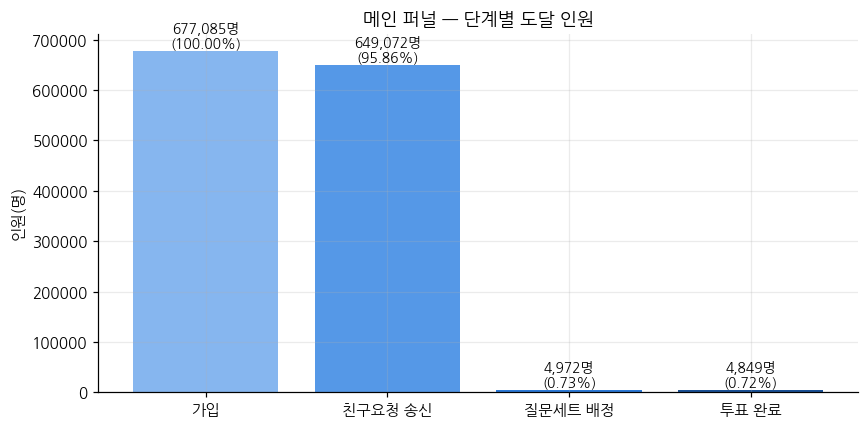

In [65]:
# 퍼널 차트 — 단계가 진행될수록 짙어지는 단일 색조(순차 팔레트)로 표현
stages = ['가입', '친구요청 송신', '질문세트 배정', '투표 완료']
counts = [n0, n1, n2, n3]
pcts = [c / n0 * 100 for c in counts]
seq_blues = ['#86b6ef', '#5598e7', '#2a78d6', '#184f95']  # 밝은 파랑 -> 짙은 파랑

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(stages, counts, color=seq_blues)
ax.set_title('메인 퍼널 — 단계별 도달 인원')
ax.set_ylabel('인원(명)')
for bar, c, p in zip(bars, counts, pcts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{c:,}명\n({p:.2f}%)',
            ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## 병목① 분석 : 학교별 가입 순번(조기가입자 vs 이후가입자 배정률 비교)

In [66]:
# 조기가입자 = 40명 이상으로 자란 학교 안에서 가입순번 40번째 미만
# 이후가입자 = 가입순번 40번째 이상 (학교 규모 무관)
early = set(user_school.loc[user_school['school_40plus'] & (user_school['join_order'] < 40), 'id'])
late = set(user_school.loc[user_school['join_order'] >= 40, 'id'])

n_early, n_late = len(early), len(late)
assigned_early = len(early & assigned_users)
assigned_late = len(late & assigned_users)

# 각 그룹의 질문세트 배정률 계산
rate_early = assigned_early / n_early * 100
rate_late = assigned_late / n_late * 100
print(f"조기가입자(1~40번째 이전) 배정률: {assigned_early:,}/{n_early:,} = {rate_early:.4f}%")
print(f"이후가입자(40번째 이후)   배정률: {assigned_late:,}/{n_late:,} = {rate_late:.4f}%")
print(f"격차: {rate_late/rate_early:.2f}배")

# 2x2 교차표(배정 여부 x 조기/이후) 만들어서 카이제곱 독립성 검정 수행
ct = pd.DataFrame({
    'assigned': [assigned_early, assigned_late],
    'not_assigned': [n_early - assigned_early, n_late - assigned_late],
}, index=['early', 'late'])

chi2, p, dof, exp = stats.chi2_contingency(ct, correction=True)  # Yates 연속성 보정
print(f"카이제곱 독립성 검정 (Yates 보정): χ²={chi2:.2f}, p={p:.4e}")

조기가입자(1~40번째 이전) 배정률: 388/151,983 = 0.2553%
이후가입자(40번째 이후)   배정률: 4,584/503,519 = 0.9104%
격차: 3.57배
카이제곱 독립성 검정 (Yates 보정): χ²=664.71, p=1.4098e-146


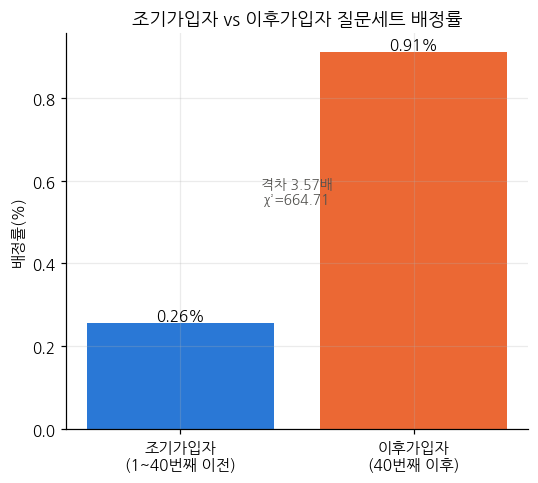

In [67]:
# 조기가입자 vs 이후가입자 배정률 비교 (두 그룹이라 categorical 2색: blue/orange)
fig, ax = plt.subplots(figsize=(5, 4.5))
bars = ax.bar(['조기가입자\n(1~40번째 이전)', '이후가입자\n(40번째 이후)'],
              [rate_early, rate_late], color=[BLUE, ORANGE])
ax.set_title('조기가입자 vs 이후가입자 질문세트 배정률')
ax.set_ylabel('배정률(%)')
for bar, v in zip(bars, [rate_early, rate_late]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{v:.2f}%',
            ha='center', va='bottom', fontsize=10)
ax.text(0.5, max(rate_early, rate_late) * 0.6, f'격차 {rate_late/rate_early:.2f}배\nχ²={chi2:.2f}',
        ha='center', transform=ax.transData, fontsize=9, color='#52514e')
plt.tight_layout()
plt.show()

## 병목② 초기 재투표의 문제 : 아하모먼트 기준 재투표율 격차

In [68]:
# 가입 후 0~72시간(3일) 내 투표 횟수 집계
vote_3d = uqr[uqr['elapsed_hours'].between(0, 72, inclusive='left')].groupby('user_id').size().rename('vote_count_3d')

# 72시간 이후에도 투표 기록이 있으면 "재투표(retained)"로 표시
after_72h = uqr[uqr['elapsed_hours'] >= 72]
retained = after_72h.groupby('user_id').size().gt(0).rename('retained')

# 투표완료 유저 전체를 대상으로 vote_count_3d, retained 두 컬럼 합치기
pop = pd.DataFrame(index=uqr['user_id'].unique())
pop = pop.join(vote_3d).join(retained)
pop['vote_count_3d'] = pop['vote_count_3d'].fillna(0).astype(int)
pop['retained'] = pop['retained'].fillna(False)

print(f"분석 대상(투표완료 유저): {len(pop):,}명")
print()

# 기준값(1~30회)을 하나씩 바꿔가며 "기준 이상 vs 미만" 그룹 간 재투표율 격차와 카이제곱·피셔 유의성 계산
rows = []
for th in range(1, 31):
    reached = pop['vote_count_3d'] >= th
    ct = pd.crosstab(reached, pop['retained'])
    if ct.shape != (2, 2):
        continue
    gap = (pop.loc[reached, 'retained'].mean() - pop.loc[~reached, 'retained'].mean()) * 100
    chi2, p_chi2, _, _ = stats.chi2_contingency(ct)
    _, p_fisher = stats.fisher_exact(ct)
    rows.append({'threshold': th, 'gap_pp': round(gap, 2), 'p_chi2': p_chi2, 'p_fisher': p_fisher})
sweep = pd.DataFrame(rows)
print('기준값(5~20회) 스윕 결과:')
print(sweep[sweep['threshold'].between(5, 20)].to_string(index=False))
print()
print(f"격차 최댓값: {sweep.loc[sweep['gap_pp'].idxmax(), 'threshold']:.0f}회")
print(f"카이제곱 p 최솟값: {sweep.loc[sweep['p_chi2'].idxmin(), 'threshold']:.0f}회")
print(f"피셔 정확검정 p 최솟값: {sweep.loc[sweep['p_fisher'].idxmin(), 'threshold']:.0f}회")

분석 대상(투표완료 유저): 4,849명

기준값(5~20회) 스윕 결과:
 threshold  gap_pp       p_chi2     p_fisher
         5   10.82 2.521179e-13 6.875773e-11
         6   11.91 5.104726e-17 1.427837e-13
         7   14.48 6.966709e-26 9.346788e-20
         8   15.32 1.416172e-30 4.731372e-23
         9   16.80 3.197467e-38 3.213258e-28
        10   17.79 1.455772e-45 2.557280e-33
        11   18.73 2.242661e-53 9.361297e-39
        12   19.22 5.771194e-58 5.521902e-42
        13   19.35 6.971637e-61 3.224042e-44
        14   19.29 1.259722e-62 1.021339e-45
        15   19.36 6.315857e-65 1.517997e-47
        16   18.98 7.804313e-65 6.223124e-48
        17   18.58 3.718030e-64 7.177883e-48
        18   18.45 2.306050e-65 4.138972e-49
        19   18.59 3.046438e-68 1.885454e-51
        20   17.94 1.919682e-65 6.432891e-50

격차 최댓값: 15회
카이제곱 p 최솟값: 22회
피셔 정확검정 p 최솟값: 23회


/tmp/ipykernel_1007/1633853850.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pop['retained'] = pop['retained'].fillna(False)


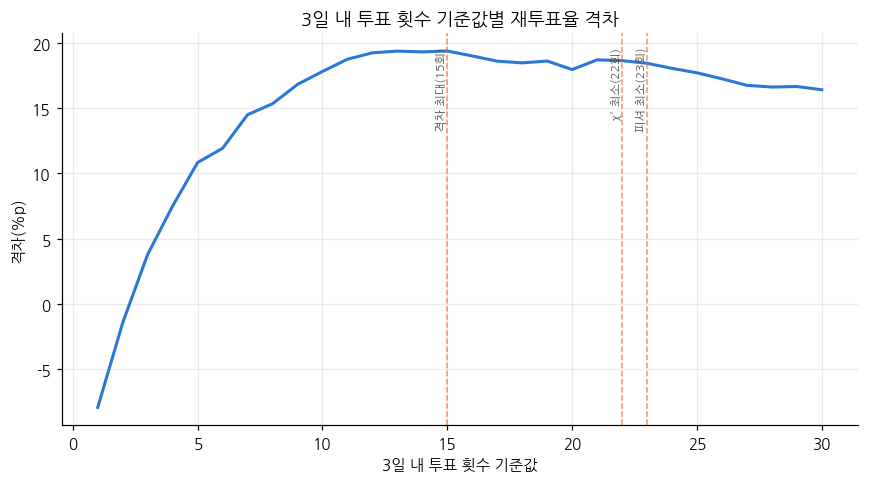

In [69]:
# 기준값(1~30회)별 재투표율 격차 곡선 — 완만하게 계속 오르는 모양이라 "특정 지점에서 꺾이는" 게 아님을 보여줌
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sweep['threshold'], sweep['gap_pp'], color=BLUE, linewidth=2)
for th, label in [(15, '격차 최대(15회)'), (22, 'χ² 최소(22회)'), (23, '피셔 최소(23회)')]:
    ax.axvline(th, color=ORANGE, linestyle='--', linewidth=1, alpha=0.7)
    ax.text(th, ax.get_ylim()[1] * 0.95, label, rotation=90, va='top', ha='right',
            fontsize=8, color='#52514e')
ax.set_title('3일 내 투표 횟수 기준값별 재투표율 격차')
ax.set_xlabel('3일 내 투표 횟수 기준값')
ax.set_ylabel('격차(%p)')
plt.tight_layout()
plt.show()

In [70]:
rng = np.random.default_rng(42)
n_boot = 300
idx = pop.index.values
best_thresholds = []

for _ in range(n_boot):
    samp_idx = rng.choice(idx, size=len(idx), replace=True)
    samp = pop.loc[samp_idx]
    best_gap, best_th = -1, None
    for th in range(5, 26):
        reached = samp['vote_count_3d'] >= th
        if reached.sum() == 0 or (~reached).sum() == 0:
            continue
        gap = samp.loc[reached, 'retained'].mean() - samp.loc[~reached, 'retained'].mean()
        if gap > best_gap:
            best_gap, best_th = gap, th
    if best_th is not None:
        best_thresholds.append(best_th)

best_thresholds = np.array(best_thresholds)
ci_low, ci_high = np.percentile(best_thresholds, [5, 95])
top_values = pd.Series(best_thresholds).value_counts().head(3)

print(f"부트스트랩 {n_boot}회 기준, '격차 최대' 기준값의 90% 신뢰구간: {ci_low:.0f}~{ci_high:.0f}회")
print(f"신뢰구간 안에서 가장 자주 나온 기준값 top3: {dict(top_values)}")
print()
print("→ 신뢰구간 안에서도 여러 값으로 흩어져 있어, 상위 빈도 구간(12~15회)을 대표 구간으로 보고")
print("  이 중 원래 격차가 최대였던 15회를 이후 격차 계산의 대표 기준값으로 사용")

부트스트랩 300회 기준, '격차 최대' 기준값의 90% 신뢰구간: 11~22회
신뢰구간 안에서 가장 자주 나온 기준값 top3: {15: np.int64(64), 13: np.int64(56), 12: np.int64(50)}

→ 신뢰구간 안에서도 여러 값으로 흩어져 있어, 상위 빈도 구간(12~15회)을 대표 구간으로 보고
  이 중 원래 격차가 최대였던 15회를 이후 격차 계산의 대표 기준값으로 사용


## 친구 수 6~40명 구간으로 한정한 재투표율 비교

In [71]:
pop['aha15'] = pop['vote_count_3d'] >= 15
r_true = pop.loc[pop['aha15'], 'retained'].mean() * 100
r_false = pop.loc[~pop['aha15'], 'retained'].mean() * 100
ct15 = pd.crosstab(pop['aha15'], pop['retained'])
chi2_15, p_chi2_15, _, _ = stats.chi2_contingency(ct15, correction=False)
odds_15, p_fisher_15 = stats.fisher_exact(ct15)

print(f"[전체 유저] 15회 이상 재투표율: {r_true:.2f}% / 15회 미만: {r_false:.2f}% "
      f"(격차 {r_true-r_false:.2f}%p)")
print(f"카이제곱 p={p_chi2_15:.4e}, 피셔 정확검정 p={p_fisher_15:.4e}")

[전체 유저] 15회 이상 재투표율: 94.96% / 15회 미만: 75.60% (격차 19.36%p)
카이제곱 p=1.5701e-65, 피셔 정확검정 p=1.5180e-47


In [72]:
# 친구 수 6~40명 구간으로 한정
# '친구 수' = 가입 후 0~72시간 내 수락(status='A')된 친구요청(송신+수신 합산)
fr_a = friendrequest[friendrequest['status'] == 'A'].copy()

send_m = fr_a.merge(signup.rename('signup_ts'), left_on='send_user_id', right_index=True, how='inner')
send_m['elapsed_hours'] = (send_m['created_at'] - send_m['signup_ts']).dt.total_seconds() / 3600
send_3d = send_m[send_m['elapsed_hours'].between(0, 72)]

recv_m = fr_a.merge(signup.rename('signup_ts'), left_on='receive_user_id', right_index=True, how='inner')
recv_m['elapsed_hours'] = (recv_m['created_at'] - recv_m['signup_ts']).dt.total_seconds() / 3600
recv_3d = recv_m[recv_m['elapsed_hours'].between(0, 72)]

conn_3d = pd.concat([
    send_3d.groupby('send_user_id').size(),
    recv_3d.groupby('receive_user_id').size(),
]).groupby(level=0).sum().rename('conn_3d')

pop2 = pop.join(conn_3d)
pop2['conn_3d'] = pop2['conn_3d'].fillna(0).astype(int)

sub = pop2[(pop2['conn_3d'] >= 6) & (pop2['conn_3d'] <= 40)]
r_true_f = sub.loc[sub['aha15'], 'retained'].mean() * 100
r_false_f = sub.loc[~sub['aha15'], 'retained'].mean() * 100
ct_f = pd.crosstab(sub['aha15'], sub['retained'])
chi2_f, p_chi2_f, _, _ = stats.chi2_contingency(ct_f, correction=False)
odds_f, p_fisher_f = stats.fisher_exact(ct_f)

print(f"[친구 수 6~40명, n={len(sub):,}] 15회 이상 재투표율: {r_true_f:.2f}% / "
      f"15회 미만: {r_false_f:.2f}% (격차 {r_true_f-r_false_f:.2f}%p)")
print(f"카이제곱 p={p_chi2_f:.4e}, 피셔 정확검정 p={p_fisher_f:.4e}")

[친구 수 6~40명, n=2,841] 15회 이상 재투표율: 94.11% / 15회 미만: 73.19% (격차 20.92%p)
카이제곱 p=4.9022e-44, 피셔 정확검정 p=1.1035e-33


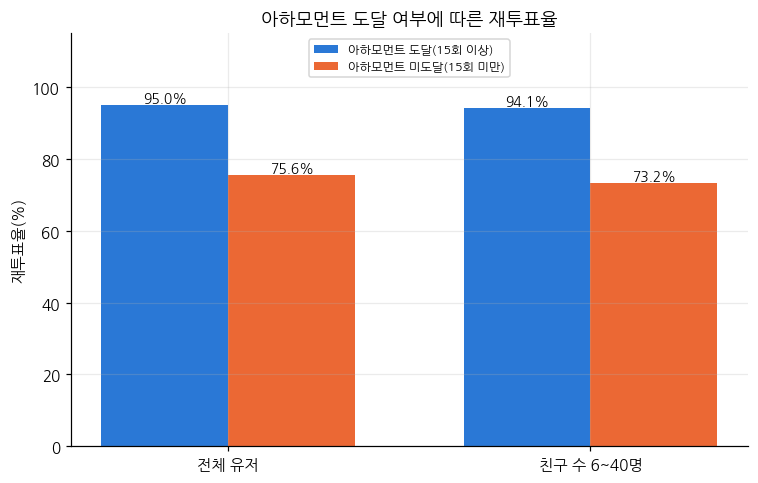

In [73]:
# 아하모먼트 도달/미도달 재투표율 격차 — 전체 유저 vs 친구 수 6~40명 구간, 그룹별 막대 비교
groups = ['전체 유저', '친구 수 6~40명']
aha_rates = [r_true, r_true_f]
no_aha_rates = [r_false, r_false_f]

x = np.arange(len(groups))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 4.5))
bars1 = ax.bar(x - width/2, aha_rates, width, label='아하모먼트 도달(15회 이상)', color=BLUE)
bars2 = ax.bar(x + width/2, no_aha_rates, width, label='아하모먼트 미도달(15회 미만)', color=ORANGE)

ax.set_title('아하모먼트 도달 여부에 따른 재투표율')
ax.set_ylabel('재투표율(%)')
ax.set_ylim(0, 115)
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=1, fontsize=8)
for bars in (bars1, bars2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{bar.get_height():.1f}%',
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

##